# How Learning Rate Shapes the Training of a Small CNN

Experiment notebook for my blog post. Question: **how does the learning rate change the training curve of a small CNN on Fashion-MNIST, and is the gap between settings bigger than seed-to-seed noise?**

Setup code (HParams, data module, model, Lightning module, `fit`) is adapted from the class notebook `hyperparameters.ipynb`.

In [ ]:
 %pip install torch torchvision lightning pandas matplotlib

In [ ]:
import logging
import random
import time
import warnings
from dataclasses import asdict, dataclass, replace
from pathlib import Path
from typing import Optional

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

try:
    import lightning as L
    from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
    from lightning.pytorch.loggers import CSVLogger
    _LIGHTNING_LOGGER = "lightning.pytorch"
except ImportError:
    import pytorch_lightning as L
    from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint
    from pytorch_lightning.loggers import CSVLogger
    _LIGHTNING_LOGGER = "pytorch_lightning"

warnings.filterwarnings("ignore", message=".*does not have many workers.*")
warnings.filterwarnings("ignore", message=".*logging interval.*")

print("torch:", torch.__version__)
print("lightning:", L.__version__)
print("GPU available:", torch.cuda.is_available())

torch: 2.14.1+cpu
lightning: 2.6.6
GPU available: False


In [ ]:
@dataclass
class HParams:
    # ---- Data
    data_dir: str = "./data"
    batch_size: int = 64
    val_fraction: float = 0.1
    train_subset: Optional[int] = None
    augment: bool = False
    num_workers: int = 0

    # ---- Model
    conv1_channels: int = 32
    conv2_channels: int = 64
    hidden_dim: int = 128
    activation: str = "relu"
    use_batchnorm: bool = True
    dropout: float = 0.25

    # ---- Optimisation
    optimizer: str = "adam"
    lr: float = 1e-3
    momentum: float = 0.9
    weight_decay: float = 0.0
    scheduler: str = "none"

    # ---- Training loop
    max_epochs: int = 5
    patience: int = 3
    seed: int = 42


hp = HParams()
pd.Series(asdict(hp), name="value").to_frame()

,value
data_dir,./data
batch_size,64
val_fraction,0.1
train_subset,None
augment,False
num_workers,0
conv1_channels,32
conv2_channels,64
hidden_dim,128
activation,relu


In [ ]:
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Mean and standard deviation of the Fashion-MNIST training pixels.
FMNIST_MEAN, FMNIST_STD = (0.2860,), (0.3530,)


class FashionMNISTDataModule(L.LightningDataModule):
    def __init__(self, hp: HParams):
        super().__init__()
        self.hp = hp
        normalize = transforms.Normalize(FMNIST_MEAN, FMNIST_STD)
        self.eval_transform = transforms.Compose([transforms.ToTensor(), normalize])

        augmentations = []
        if hp.augment:  # <-- hyperparameter: augment
            augmentations = [transforms.RandomCrop(28, padding=2),
                             transforms.RandomHorizontalFlip()]
        self.train_transform = transforms.Compose([*augmentations, transforms.ToTensor(), normalize])

    def prepare_data(self):
        # Lightning calls this on a single process.
        datasets.FashionMNIST(self.hp.data_dir, train=True, download=True)
        datasets.FashionMNIST(self.hp.data_dir, train=False, download=True)

    def setup(self, stage=None):
        # Two views of the same 60k images: one with training transforms, one without.
        train_view = datasets.FashionMNIST(self.hp.data_dir, train=True, transform=self.train_transform)
        eval_view = datasets.FashionMNIST(self.hp.data_dir, train=True, transform=self.eval_transform)

        n_total = len(train_view)
        n_val = int(n_total * self.hp.val_fraction)  # <-- hyperparameter: val_fraction
        generator = torch.Generator().manual_seed(self.hp.seed)
        indices = torch.randperm(n_total, generator=generator).tolist()
        val_idx, train_idx = indices[:n_val], indices[n_val:]

        if self.hp.train_subset is not None:  # <-- hyperparameter: train_subset
            train_idx = train_idx[: self.hp.train_subset]

        self.train_ds = Subset(train_view, train_idx)
        self.val_ds = Subset(eval_view, val_idx)
        self.test_ds = datasets.FashionMNIST(self.hp.data_dir, train=False, transform=self.eval_transform)

    def _loader(self, dataset, batch_size, shuffle):
        return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                          num_workers=self.hp.num_workers,
                          persistent_workers=self.hp.num_workers > 0)

    def train_dataloader(self):
        return self._loader(self.train_ds, self.hp.batch_size, shuffle=True)  # <-- hyperparameter: batch_size

    def val_dataloader(self):
        # The evaluation batch size only affects speed, never the result.
        return self._loader(self.val_ds, 512, shuffle=False)

    def test_dataloader(self):
        return self._loader(self.test_ds, 512, shuffle=False)

In [ ]:
ACTIVATIONS = {"relu": nn.ReLU, "leaky_relu": nn.LeakyReLU, "gelu": nn.GELU, "tanh": nn.Tanh}


class SmallCNN(nn.Module):
    def __init__(self, hp: HParams, num_classes: int = 10):
        super().__init__()
        act = ACTIVATIONS[hp.activation]            # <-- hyperparameter: activation
        c1, c2 = hp.conv1_channels, hp.conv2_channels  # <-- hyperparameters: width

        def conv_block(in_ch, out_ch):
            layers = [nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1)]
            if hp.use_batchnorm:                    # <-- hyperparameter: use_batchnorm
                layers.append(nn.BatchNorm2d(out_ch))
            layers += [act(), nn.MaxPool2d(2)]
            return nn.Sequential(*layers)

        self.features = nn.Sequential(conv_block(1, c1), conv_block(c1, c2))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(hp.dropout),                 # <-- hyperparameter: dropout
            nn.Linear(c2 * 7 * 7, hp.hidden_dim),   # <-- hyperparameter: hidden_dim
            act(),
            nn.Dropout(hp.dropout),
            nn.Linear(hp.hidden_dim, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


model = SmallCNN(hp)
print(model)
print(f"\ntrainable parameters: {count_parameters(model):,}")

SmallCNN(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.25, inplace=False)
    (2): Linear(in_features=3136, out_features=128, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.25, inplace=False)
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)

trainable parameters: 421,834


In [ ]:
class LitClassifier(L.LightningModule):
    def __init__(self, hp: HParams):
        super().__init__()
        self.hp = hp
        self.save_hyperparameters(asdict(hp))  # logged + stored in checkpoints
        self.model = SmallCNN(hp)
        self.loss_fn = nn.CrossEntropyLoss()

    def forward(self, x):
        return self.model(x)

    def _shared_step(self, batch, stage: str):
        x, y = batch
        logits = self(x)
        loss = self.loss_fn(logits, y)
        acc = (logits.argmax(dim=1) == y).float().mean()
        # on_epoch=True: Lightning averages over the epoch (weighted by batch size).
        self.log(f"{stage}_loss", loss, on_step=False, on_epoch=True, prog_bar=True)
        self.log(f"{stage}_acc", acc, on_step=False, on_epoch=True, prog_bar=True)
        return loss

    def training_step(self, batch, batch_idx):
        return self._shared_step(batch, "train")

    def validation_step(self, batch, batch_idx):
        self._shared_step(batch, "val")

    def test_step(self, batch, batch_idx):
        self._shared_step(batch, "test")

    def configure_optimizers(self):
        hp = self.hp
        params = self.parameters()

        # <-- hyperparameters: optimizer, lr, momentum, weight_decay
        if hp.optimizer == "sgd":
            optimizer = torch.optim.SGD(params, lr=hp.lr, momentum=hp.momentum, weight_decay=hp.weight_decay)
        elif hp.optimizer == "adam":
            optimizer = torch.optim.Adam(params, lr=hp.lr, weight_decay=hp.weight_decay)
        elif hp.optimizer == "adamw":
            optimizer = torch.optim.AdamW(params, lr=hp.lr, weight_decay=hp.weight_decay)
        else:
            raise ValueError(f"unknown optimizer: {hp.optimizer}")

        # <-- hyperparameter: scheduler
        if hp.scheduler == "none":
            return optimizer
        if hp.scheduler == "step":
            scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=max(1, hp.max_epochs // 3), gamma=0.1)
        elif hp.scheduler == "cosine":
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=hp.max_epochs)
        else:
            raise ValueError(f"unknown scheduler: {hp.scheduler}")
        return {"optimizer": optimizer, "lr_scheduler": {"scheduler": scheduler, "interval": "epoch"}}

In [ ]:
def load_history(log_dir) -> pd.DataFrame:
    """Read Lightning's metrics.csv and return one row per epoch."""
    df = pd.read_csv(Path(log_dir) / "metrics.csv")
    cols = [c for c in ["train_loss", "val_loss", "train_acc", "val_acc"] if c in df.columns]
    return df.groupby("epoch")[cols].mean().reset_index()


def fit(hp: HParams, run_name: str = "run", verbose: bool = True, checkpoint: bool = False):
    """Train one model from a config. Returns (trainer, model, datamodule, history)."""
    for name in (_LIGHTNING_LOGGER, "lightning.fabric", "lightning_fabric"):
        logging.getLogger(name).setLevel(logging.INFO if verbose else logging.ERROR)
    L.seed_everything(hp.seed, workers=True)  # <-- hyperparameter: seed

    datamodule = FashionMNISTDataModule(hp)
    model = LitClassifier(hp)
    logger = CSVLogger("logs", name=run_name)

    callbacks = [EarlyStopping(monitor="val_loss", mode="min", patience=hp.patience)]  # <-- hyperparameter: patience
    if checkpoint:
        callbacks.append(ModelCheckpoint(monitor="val_acc", mode="max", save_top_k=1))

    trainer = L.Trainer(
        max_epochs=hp.max_epochs,          # <-- hyperparameter: max_epochs
        accelerator="auto",                # GPU if there is one, otherwise CPU
        devices=1,
        logger=logger,
        callbacks=callbacks,
        enable_checkpointing=checkpoint,
        enable_progress_bar=verbose,
        enable_model_summary=verbose,
        log_every_n_steps=10,
    )
    trainer.fit(model, datamodule=datamodule)
    history = load_history(logger.log_dir)
    return trainer, model, datamodule, history

## Fixed setup

Everything below is held constant except `lr` (and `seed`, which is repeated on purpose):

- Data: Fashion-MNIST, 10,000 training images (subset), 6,000 validation images (10% of the 60k training set), test set untouched
- Model: SmallCNN (32, 64 conv channels, hidden 128, ReLU, BatchNorm, dropout 0.25)
- Optimizer: Adam, batch size 64, no scheduler, no weight decay
- Epochs: 8, early stopping disabled (`patience=100`) so every run is equally long
- Seeds: 0, 1, 2 for every learning rate

In [ ]:
BASE = replace(HParams(), train_subset=10_000, max_epochs=8, patience=100,
               optimizer="adam", batch_size=64, weight_decay=0.0, scheduler="none")
LRS = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
SEEDS = [0, 1, 2]

runs = {}   # (lr, seed) -> history
for lr in LRS:
    for seed in SEEDS:
        hp_i = replace(BASE, lr=lr, seed=seed)
        _, _, _, h = fit(hp_i, run_name=f"lr_{lr:g}/seed_{seed}", verbose=False)
        runs[(lr, seed)] = h
        print(f"lr={lr:<7g} seed={seed}  best val_acc={h['val_acc'].max():.4f}  final val_loss={h['val_loss'].iloc[-1]:.4f}")

100%|██████████| 26.4M/26.4M [00:01<00:00, 19.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 304kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.65MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 21.1MB/s]
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


lr=1e-05   seed=0  best val_acc=0.8178  final val_loss=0.5390


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


lr=1e-05   seed=1  best val_acc=0.8237  final val_loss=0.5405


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


lr=1e-05   seed=2  best val_acc=0.8163  final val_loss=0.5432


... (20 outputs left out)

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


lr=0.1     seed=1  best val_acc=0.1030  final val_loss=2.3090


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


lr=0.1     seed=2  best val_acc=0.7390  final val_loss=0.6982


## Figure 1: learning curves (mean over 3 seeds, shaded = min/max)

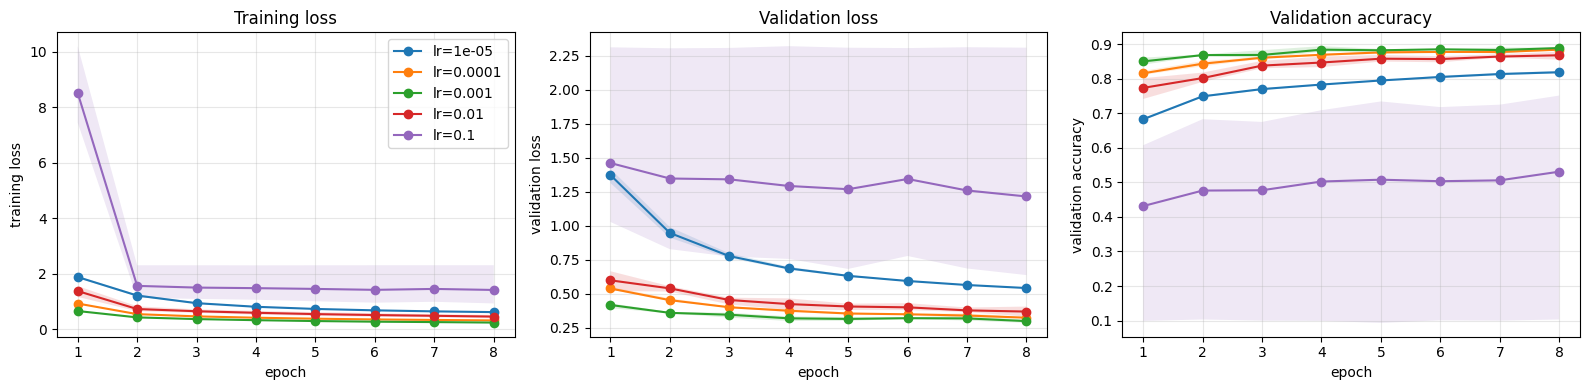

In [31]:
import numpy as np

def stack(lr, metric):
    return np.stack([runs[(lr, s)][metric].values for s in SEEDS])

fig1, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, metric, ylabel in zip(
    axes,
    ["train_loss", "val_loss", "val_acc"],
    ["training loss", "validation loss", "validation accuracy"]
):
    for lr in LRS:
        a = stack(lr, metric)
        ep = runs[(lr, SEEDS[0])]["epoch"].values + 1

        ax.plot(ep, a.mean(0), "o-", label=f"lr={lr:g}")
        ax.fill_between(ep, a.min(0), a.max(0), alpha=0.15)

    ax.set(xlabel="epoch", ylabel=ylabel, title=ylabel.capitalize())
    ax.grid(alpha=0.3)

axes[0].legend()
fig1.tight_layout()
fig1.savefig("fig1_learning_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## Table 1 and Figure 2: final numbers and sensitivity

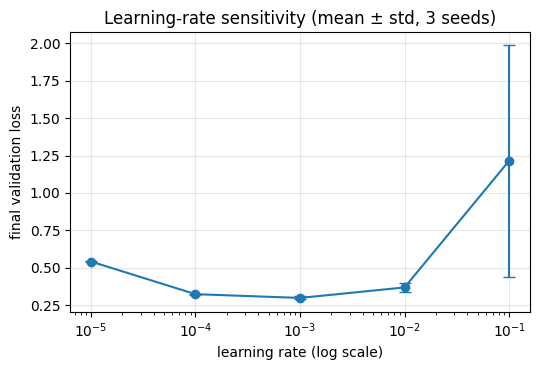

In [32]:
fig2, ax = plt.subplots(figsize=(5.5, 3.8))

m = table["final_val_loss_mean"].values
s = table["final_val_loss_std"].values

ax.errorbar(LRS, m, yerr=s, fmt="o-", capsize=4)
ax.set_xscale("log")

ax.set(
    xlabel="learning rate (log scale)",
    ylabel="final validation loss",
    title="Learning-rate sensitivity (mean ± std, 3 seeds)"
)

ax.grid(alpha=0.3)
fig2.tight_layout()
fig2.savefig("fig2_sensitivity.png", dpi=300, bbox_inches="tight")
plt.show()

## Optional: test set, once, for the best learning rate

Only run this at the very end, after choosing the best `lr` from the **validation** numbers above.

In [21]:
import os
os.environ["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = "1"

best_lr = table["best_val_acc_mean"].idxmax()
print("best lr by validation accuracy:", best_lr)
hp_best = replace(BASE, lr=best_lr, seed=0)
trainer, model, dm, h = fit(hp_best, run_name="best_lr_test", verbose=False, checkpoint=True)
print(trainer.test(model, datamodule=dm, ckpt_path="best"))

best lr by validation accuracy: 0.001


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.13/dist-packages/lightning/fabric/utilities/cloud_io.py:73: Environment variable TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD detected, since the`weights_only` argument was not explicitly passed to `torch.load`, forcing weights_only=False.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_acc          │    0.8816999793052673     │
│         test_loss         │    0.3263680040836334     │
└───────────────────────────┴───────────────────────────┘

[{'test_loss': 0.3263680040836334, 'test_acc': 0.8816999793052673}]


In [34]:
from google.colab import files

files.download("fig1_learning_curves.png")
files.download("fig2_sensitivity.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>